# Check geometry

In [3]:
import json
import numpy as np
from pathlib import Path

from ase import Atoms
from ase.optimize import BFGS
from ase.io import read, write
from tblite.ase import TBLite

from qgee.qubit_hamil import *

import matplotlib.pyplot as plt

In [42]:
def find_repo_root(start: Path | None = None) -> Path:
    """Find the repository root by locating pyproject.toml."""
    start = (start or Path.cwd()).resolve()

    for directory in (start, *start.parents):
        if (directory / "pyproject.toml").is_file():
            return directory

    raise FileNotFoundError(
        f"Could not find pyproject.toml starting from {start}"
    )


REPO_ROOT = find_repo_root()
GEOMETRIES_DIR = REPO_ROOT / "geometries"

def load_geometry(name: str) -> dict:
    """Load a molecule's initial geometry."""
    input_path = GEOMETRIES_DIR / f"initial_{name}.json"

    with input_path.open("r") as f:
        return json.load(f)
    
def optimize_geometry(name: str, data: dict, datatype: str, save: bool = True) -> None:
    """Optimize a molecular geometry and save outputs in geometries/name/."""
    # Create a dedicated directory for this molecule's outputs
    if save:
        output_dir = GEOMETRIES_DIR / name.lower()
        output_dir.mkdir(parents=True, exist_ok=True)
    else:
        output_dir = None

    if datatype == "json":
        symbols = data["symbols_list"][0]
        positions = data["geometry_list"][0]
    elif datatype == "str":
        atom_strings = [atom.split() for atom in data.split(";")]

        symbols = [atom[0] for atom in atom_strings]
        positions = [[float(x) for x in atom[1:4]] for atom in atom_strings]

    atoms = Atoms(symbols=symbols, positions=positions)
    atoms.calc = TBLite(method="GFN2-xTB", verbosity=0)

    # Optimize
    if save:
        optimizer = BFGS(
            atoms,
            trajectory=str(output_dir / "optimization.traj"),
            logfile=str(output_dir / "optimization.log"),
            maxstep=0.05,
        )
    else:
        optimizer = BFGS(
            atoms,
            maxstep=0.05,
        )

    converged = optimizer.run(fmax=0.01, steps=1000)

    # Report results
    forces = atoms.get_forces()
    force_norms = np.linalg.norm(forces, axis=1)

    print(f"Converged: {converged}")
    print(f"Energy: {atoms.get_potential_energy():.8f} eV")
    print(f"Maximum force: {force_norms.max():.6f} eV/Å")
    print(f"RMS force: {np.sqrt(np.mean(force_norms**2)):.6f} eV/Å")

    # Save optimized structure
    if save:
        write(str(output_dir / "optimized.xyz"), atoms)
    else:
        print("Skipping saving optimized geometry")

    output_data = {
        "symbols_list": [symbols],
        "geometry_list": [atoms.get_positions().tolist()],
    }

    if save:
        output_path = output_dir / "optimized_gfn2xtb.json"
        with output_path.open("w") as f:
            json.dump(output_data, f, indent=2)
        print("Saved optimized geometry")
    else:
        print("Skipping saving optimized geometry JSON")
        print("Optimized geometry:", output_data)

def plot_optimization_progress(name):
    """Plot the energy and maximum force during the optimization process."""
    # Trajectory saved by optimize_geometry()
    output_dir = GEOMETRIES_DIR / name.lower()
    trajectory_path = output_dir / "optimization.traj"

    trajectory = read(str(trajectory_path), index=":")

    energies = np.array([
        frame.get_potential_energy() for frame in trajectory
    ])
    max_forces = np.array([
        np.linalg.norm(frame.get_forces(), axis=1).max()
        for frame in trajectory
    ])

    fig, ax1 = plt.subplots()

    ax1.plot(energies, label="Energy (eV)")
    ax1.set_xlabel("Trajectory frame")
    ax1.set_ylabel("Energy (eV)")

    ax2 = ax1.twinx()
    ax2.plot(max_forces, linestyle="--", label="Maximum force")
    ax2.set_ylabel("Maximum force (eV/Å)")

    ax1.legend(loc="upper left")
    ax2.legend(loc="upper right")

    plt.title(f"{name} optimization progress")
    fig.tight_layout()
    plt.show()

### DMABN

In [9]:
dmabn_data = load_geometry("dmabn")
symbols = dmabn_data["symbols_list"][0]
positions = dmabn_data["geometry_list"][0]
positions

[[0, 0, 0],
 [0.699, 1.211, 0],
 [-0.699, 1.211, 0],
 [-1.397, 0, 0],
 [-0.699, -1.211, 0],
 [0.699, -1.211, 0],
 [2.837, 0, 0],
 [3.997, 0, 0],
 [-2.797, 0, 0],
 [-3.497, 1.212, 0],
 [-3.497, -1.212, 0],
 [1.234, 2.138, 0],
 [-1.234, 2.138, 0],
 [-1.234, -2.138, 0],
 [1.234, -2.138, 0],
 [-4.037, 1.746, 0.89],
 [-4.037, 1.746, -0.89],
 [-3.497, 2.212, 0],
 [-4.037, -1.746, 0.89],
 [-4.037, -1.746, -0.89],
 [-3.497, -2.212, 0]]

In [ ]:
dmabn_data = load_geometry("dmabn")
optimize_geometry("dmabn", dmabn_data, datatype="json")

Converged: True
Energy: -820.90089158 eV
Maximum force: 0.004791 eV/Å
RMS force: 0.003277 eV/Å
Saved optimized geometry


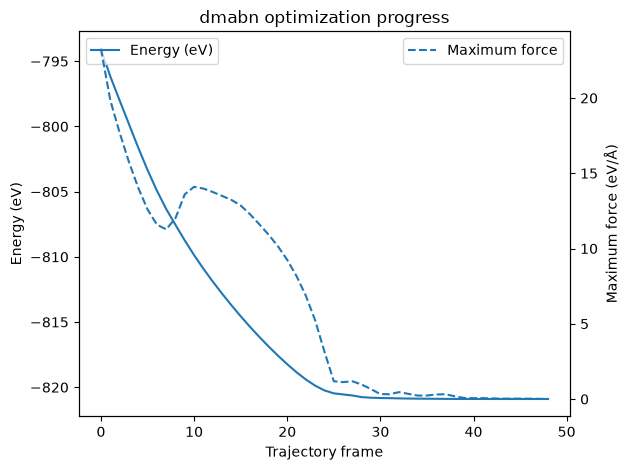

In [11]:
plot_optimization_progress("dmabn")

### Toy model

In [ ]:
toymodel_data = load_geometry("toymodel")
optimize_geometry("toymodel", toymodel_data, datatype="json")

Converged: True
Energy: -963.79888464 eV
Maximum force: 0.009797 eV/Å
RMS force: 0.006276 eV/Å
Saved optimized geometry


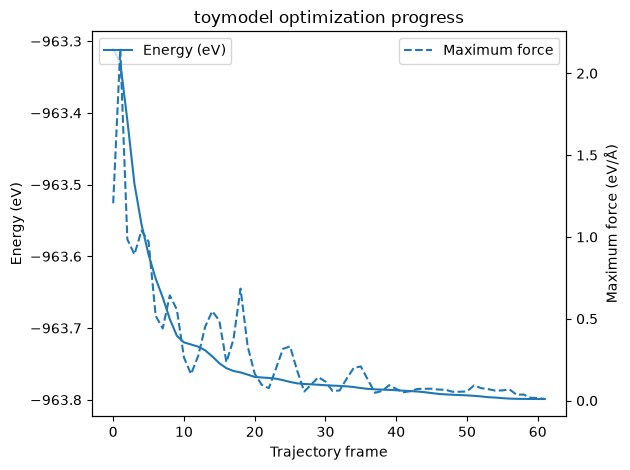

In [15]:
plot_optimization_progress("toymodel")

### Level 1

In [41]:
h2 = geometry_for_molecule("H2")
optimize_geometry("H2", h2, datatype="str", save=False)

      Step     Time          Energy          fmax
BFGS:    0 14:36:47      -26.715276        1.258166
BFGS:    1 14:36:47      -26.739816        0.153019
BFGS:    2 14:36:47      -26.740245        0.020234
BFGS:    3 14:36:47      -26.740253        0.000378
Converged: True
Energy: -26.74025283 eV
Maximum force: 0.000378 eV/Å
RMS force: 0.000378 eV/Å
Skipping saving optimized geometry
Skipping saving optimized geometry JSON
Optimized geometry: {'symbols_list': [['H', 'H']], 'geometry_list': [[[0.0, 0.0, -0.020841689292895225], [0.0, 0.0, 0.7558416892928952]]]}


In [43]:
lih = geometry_for_molecule("LiH")
optimize_geometry("LiH", lih, datatype="str", save=False)

      Step     Time          Energy          fmax
BFGS:    0 14:39:18      -21.205239        0.968963
BFGS:    1 14:39:18      -21.230990        0.889844
BFGS:    2 14:39:18      -21.302594        0.516922
BFGS:    3 14:39:18      -21.328046        0.047238
BFGS:    4 14:39:18      -21.328202        0.009661
Converged: True
Energy: -21.32820196 eV
Maximum force: 0.009661 eV/Å
RMS force: 0.009661 eV/Å
Skipping saving optimized geometry
Skipping saving optimized geometry JSON
Optimized geometry: {'symbols_list': [['Li', 'H']], 'geometry_list': [[[-9.575624825040523e-18, -4.897114860427427e-19, 0.1096557804523731], [8.689455761436262e-18, -4.622000291271315e-19, 1.4853442195476267]]]}


In [44]:
beh2 = geometry_for_molecule("BeH2")
optimize_geometry("BeH2", beh2, datatype="str", save=False)

      Step     Time          Energy          fmax
BFGS:    0 14:39:48      -46.683469        0.628587
BFGS:    1 14:39:48      -46.693878        0.529744
BFGS:    2 14:39:48      -46.716204        0.094025
BFGS:    3 14:39:48      -46.716800        0.011203
BFGS:    4 14:39:48      -46.716809        0.000200
Converged: True
Energy: -46.71680872 eV
Maximum force: 0.000200 eV/Å
RMS force: 0.000163 eV/Å
Skipping saving optimized geometry
Skipping saving optimized geometry JSON
Optimized geometry: {'symbols_list': [['H', 'Be', 'H']], 'geometry_list': [[[3.3249216584564055e-17, 1.004572591301501e-16, -1.279375376042048], [1.4480367651521797e-17, -1.0764484212969411e-16, -1.0401194503930976e-16], [-4.951236492071631e-17, -7.964939996124474e-19, 1.279375376042048]]]}
